In [1]:
pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
from tfcv import plot_convolution, plot_results, display_dataset

In [3]:
# MNIST image dataset using keras built-in function
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

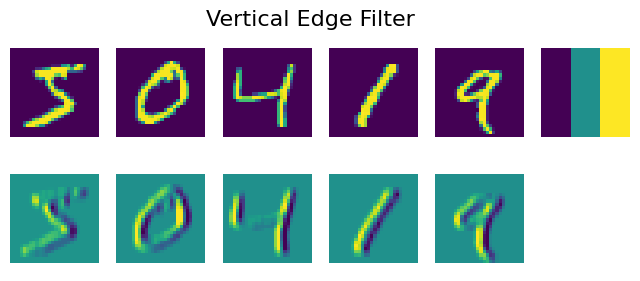

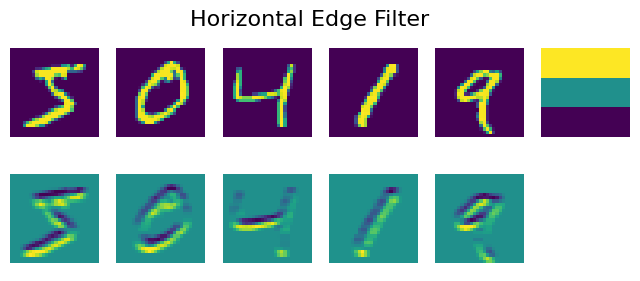

In [6]:
plot_convolution(x_train[:5], [[-1., 0., 1.], [-1.,0., 1.], [-1., 0., 1.]],
                 'Vertical Edge Filter')
plot_convolution(x_train[:5], [[1., 1., 1.], [0., 0., 0.], [-1., -1., -1.]],
                 'Horizontal Edge Filter')

In [7]:
model = keras.models.Sequential([
    keras.layers.Conv2D(filters=9, kernel_size=(5, 5),
                        input_shape=(28, 28, 1), activation = 'relu'),
    keras.layers.Flatten(),
    keras.layers.Dense(10)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['acc'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 9)      │           234 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5184)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        51,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,084 (203.45 KB)

 Trainable params: 52,084 (203.45 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
x_train_c = np.expand_dims(x_train, 3)
x_test_c = np.expand_dims(x_test, 3)
hist = model.fit(x_train_c, y_train,
                 validation_data=(x_test_c, y_test), epochs = 5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 13ms/step - acc: 0.9405 - loss: 0.2109 - val_acc: 0.9736 - val_loss: 0.0888
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - acc: 0.9764 - loss: 0.0842 - val_acc: 0.9800 - val_loss: 0.0637
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - acc: 0.9815 - loss: 0.0632 - val_acc: 0.9812 - val_loss: 0.0623
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 13ms/step - acc: 0.9841 - loss: 0.0542 - val_acc: 0.9828 - val_loss: 0.0520
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - acc: 0.9857 - loss: 0.0481 - val_acc: 0.9846 - val_loss: 0.0525


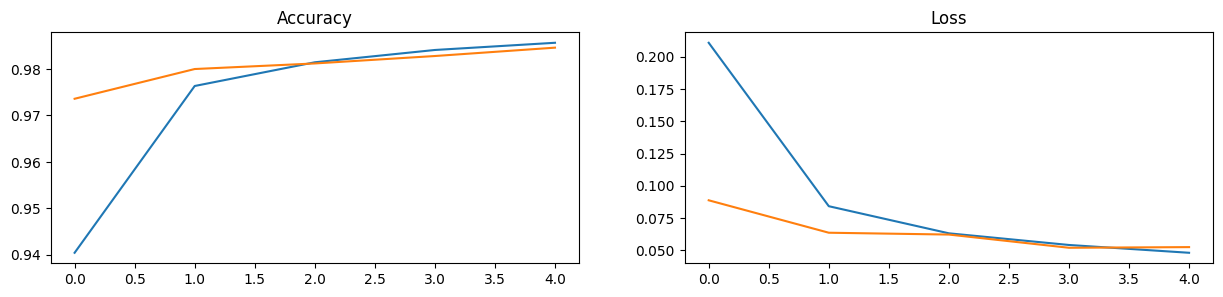

In [10]:
plot_results(hist)

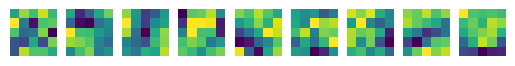

In [11]:
fig, ax = plt.subplots(1, 9)
w = model.layers[0].weights[0]
for i in range(9):
  ax[i].imshow(w[..., 0, i])
  ax[i].axis('off')

**Task**: Train the same network with 3x3 filters and visualize them.
- Do you see more familiar patterns ?

In [13]:
model1 = keras.models.Sequential([
    keras.layers.Conv2D(filters=10, kernel_size=(5, 5),
                        input_shape=(28, 28, 1),
                        activation='relu'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(filters=20, kernel_size=(5, 5),
                        activation='relu'),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(10)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model1.compile(loss=keras.losses.SparseCategoricalCrossentropy(
    from_logits=True), metrics=['acc'])
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 10)     │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 20)       │         5,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,490 (33.16 KB)

 Trainable params: 8,490 (33.16 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
hist1 = model1.fit(x_train_c, y_train,
                   validation_data=(x_test_c, y_test), epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 22ms/step - acc: 0.9393 - loss: 0.2093 - val_acc: 0.9790 - val_loss: 0.0686
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 39s 21ms/step - acc: 0.9793 - loss: 0.0690 - val_acc: 0.9856 - val_loss: 0.0489
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - acc: 0.9844 - loss: 0.0519 - val_acc: 0.9853 - val_loss: 0.0448
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - acc: 0.9870 - loss: 0.0431 - val_acc: 0.9895 - val_loss: 0.0342
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 20ms/step - acc: 0.9888 - loss: 0.0377 - val_acc: 0.9884 - val_loss: 0.0362


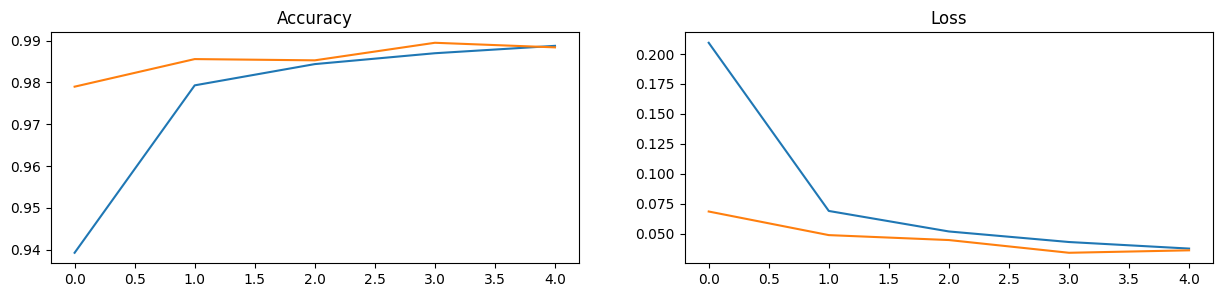

In [16]:
plot_results(hist1)

In [17]:
model1.save('full_model.h5')

In [18]:
model1.save('full_model1.keras')

In [20]:
model1.save_weights('full_weights.weights.h5')

In [29]:
predictions = model1.predict(x_test_c[:5])
print("Predicted Classes: ", np.argmax(predictions, axis=1))
print("Actual Classes: ", y_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Predicted Classes:  [7 2 1 0 4]
Actual Classes:  [7 2 1 0 4]


In [31]:
print(x_test_c.shape)
print(y_test.shape)

(10000, 28, 28, 1)
(10000,)
